# Lohoff Figure 2d recreation

Run TissueAgent from the supplied data and reference, with explicit final figures, validation, and a reproduction report. Complete run artifacts and execution state are retained under `cached/figure_recreation_lohoff-2d/`; this folder is ignored by Git. No prior run is deleted.

The supplied AnnData lacks the original segmentation/contact network. The report must distinguish the documented centroid-neighbor approximation from exact reproduction of the authors' analysis.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import shutil
import socket
import subprocess
import sys
from datetime import datetime, timezone

from IPython.display import Image, Markdown, display

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "pyproject.toml").exists():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "pyproject.toml").exists(), "Run from demo/ or the repository root."
TASK_NAME = "figure_recreation_lohoff-2d"
TASK_ID = "notebook_lohoff_2d_with_report"
MODEL = "gpt-5.5"
DATA_DIR = REPO_ROOT / "demo/data"
DATASETS = [DATA_DIR / "dataset_lohoff_et_al_seqfish.h5ad"]
REFERENCE = DATA_DIR / "reference_lohoff-2d.png"
ATTACHMENTS = [REFERENCE, DATA_DIR / "instructions_lohoff-2d.md"]
INPUTS = [*DATASETS, *ATTACHMENTS]
OUTPUT_DIR = REPO_ROOT / "cached" / TASK_NAME
PROMPT = "Reproduce the cell-cell contact map in reference_lohoff-2d.png from dataset_lohoff_et_al_seqfish.h5ad, using instructions_lohoff-2d.md. Use the supplied celltype_mapped_refined labels and spatial coordinates; parse embryo/z-slice from cell IDs. Exclude Low quality cells and report exact per-stratum counts. The h5ad lacks segmentation polygons and a stored neighbor graph. Use the instructions' documented fallback: an undirected, symmetric 10-nearest-neighbor graph within each embryo/z stratum, no self edges, each undirected edge counted once. This is a centroid-neighbor approximation, not the original expanded-polygon contact network; report that limitation. Use 500 label permutations without replacement within each stratum and random seed 0. Preserve label counts. Compute the written statistic p_ab = mean(C_ab_permuted >= C_ab_observed) exactly, then average across strata where both labels are represented. The instructions' prose reverses the meaning of this tail probability: low p indicates an observed excess of contacts (integration), while high p indicates depletion (segregation). Explicitly document this discrepancy; keep the formula unchanged and label the pink low-p end Integrated and blue high-p end Segregated. Cluster the calculated mean matrix using Euclidean distance and complete linkage, applying the same order to both axes. Do not force the published row order or matrix values. Render a lower-triangular heatmap including the diagonal, both dendrograms, colored annotation strips, diagonal labels, and the horizontal Integrated-to-Segregated scale. Save the square mean matrix with labeled index/columns as outputs/tables/contact_probabilities.csv, matching integer stratum support counts as outputs/tables/pair_support.csv, the calculated label order as a JSON list in outputs/tables/cluster_order.json, linkage as outputs/tables/linkage.csv, observed/permuted counts and per-stratum matrices, and long-form displayed values in outputs/tables/plotted_data.csv. Save the accepted final figure as outputs/final_figure.png and outputs/final_figure.pdf, executable plotting/analysis code as outputs/plotting_code.py, a cell-type color mapping as outputs/tables/colormap.yaml, machine-readable analysis metadata as outputs/tables/analysis_metadata.json, and a detailed reproduction report as outputs/reports/reproduction_report.md. The report must describe input fields, exclusions and sample sizes, actual computations and seeds, approximations and missing inputs, visual comparison and unresolved differences. Inspect the final PNG against the reference. The final PNG must be the requested figure, never a diagnostic grid or comparison montage. Use only the supplied inputs; do not retrieve prior TissueAgent/baseline reproductions. Do not fabricate cells, genes, computed statistics, or labels, alter individual coordinates to match an image, or paste reference pixels into the result. Document colors estimated from the reference."
INPUT_RECORDS = []
for path in INPUTS:
    assert path.is_file(), f"Missing input: {path}"
    with path.open("rb") as stream:
        digest = hashlib.file_digest(stream, "sha256").hexdigest()
    role = "dataset" if path in DATASETS else "reference" if path == REFERENCE else "instructions"
    INPUT_RECORDS.append({"role": role, "path": str(path), "name": path.name, "sha256": digest})
print(json.dumps({"task": TASK_NAME, "model": MODEL, "inputs": INPUT_RECORDS,
                  "supplied_colormap": False, "output_dir": str(OUTPUT_DIR)}, indent=2))


{
  "task": "figure_recreation_lohoff-2d",
  "model": "gpt-5.5",
  "inputs": [
    {
      "role": "dataset",
      "path": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/dataset_lohoff_et_al_seqfish.h5ad",
      "name": "dataset_lohoff_et_al_seqfish.h5ad",
      "sha256": "0588f810603cf3756a5a87d9730465a8968bb18f9c31d1b24e38f1d008305d70"
    },
    {
      "role": "reference",
      "path": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/reference_lohoff-2d.png",
      "name": "reference_lohoff-2d.png",
      "sha256": "c835e79968d772ebef470b82d5eee217dd4da06954b9d9f1884ded46d623c503"
    },
    {
      "role": "instructions",
      "path": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/instructions_lohoff-2d.md",
      "name": "instructions_lohoff-2d.md",
      "sha256": "015505925f50b00a45bdd6a5ebc37ecd8e66927d907f2ee0389b77e1b505ff6c"
    }
  ],
  "supplied_colormap": false,
  "output_dir": "/Users/wenduoc/new_TissueAgent/TissueAgent/cached/figure_recreation_loh

## Run the CLI

Set `OPENAI_API_KEY` in the notebook environment. A fresh run makes model calls; a completed local run is reused only if model, prompt, and input hashes match. Choose a new `OUTPUT_DIR` when changing settings or requesting another fresh run. Logs, state, intermediate attempts, final figures, and reports are retained under `cached/` rather than deleted.


In [2]:
manifest_path = OUTPUT_DIR / "run_manifest.json"
metrics_path = OUTPUT_DIR / "metrics.json"
if OUTPUT_DIR.is_dir() and manifest_path.is_file() and metrics_path.is_file():
    manifest = json.loads(manifest_path.read_text())
    metrics = json.loads(metrics_path.read_text())
    terminal_state = metrics.get("outcome", {}).get("terminal_state")
    expected_hashes = {record["name"]: record["sha256"] for record in INPUT_RECORDS}
    cached_hashes = {record["name"]: record["sha256"] for record in manifest["inputs"]}
    assert terminal_state == "completed" and manifest.get("cli_exit_code") == 0
    assert manifest.get("supplied_colormap") is False
    assert manifest.get("prompt") == PROMPT, "Prompt changed; choose a new OUTPUT_DIR."
    assert manifest.get("model") == MODEL, "Model changed; choose a new OUTPUT_DIR."
    assert cached_hashes == expected_hashes, "Inputs changed; choose a new OUTPUT_DIR."
    print(json.dumps({
        "terminal_state": terminal_state,
        "elapsed_seconds": manifest["elapsed_seconds"],
        "output_dir": str(OUTPUT_DIR),
        "reused_completed_output": True,
    }, indent=2))
else:
    if OUTPUT_DIR.exists():
        raise RuntimeError(f"{OUTPUT_DIR} already exists. Choose a new OUTPUT_DIR for a fresh run.")
    assert os.environ.get("OPENAI_API_KEY"), "Set OPENAI_API_KEY in the notebook environment for a fresh run."
    OUTPUT_DIR.mkdir(parents=True)
    STATE_ROOT = OUTPUT_DIR / "state"
    with socket.socket() as sock:
        sock.bind(("127.0.0.1", 0))
        gateway_port = sock.getsockname()[1]
    env = os.environ.copy()
    env.update({
        "TISSUEAGENT_STATE_ROOT": str(STATE_ROOT),
        "TISSUEAGENT_GATEWAY_PORT": str(gateway_port),
        "TISSUEAGENT_ORCHESTRATION_REASONING_EFFORT": "medium",
        "TISSUEAGENT_WORKER_REASONING_EFFORT": "high",
        "NUMBA_CACHE_DIR": str(OUTPUT_DIR / "cache/numba"),
        "MPLCONFIGDIR": str(OUTPUT_DIR / "cache/matplotlib"),
        "XDG_CACHE_HOME": str(OUTPUT_DIR / "cache/xdg"),
        "IPYTHONDIR": str(OUTPUT_DIR / "cache/ipython"),
        "JUPYTER_RUNTIME_DIR": str(OUTPUT_DIR / "cache/jupyter_runtime"),
        "PYTHONPATH": str(REPO_ROOT / "src") + os.pathsep + str(REPO_ROOT),
        "PATH": str(Path(sys.executable).parent) + os.pathsep + env.get("PATH", ""),
    })
    for key in ["NUMBA_CACHE_DIR", "MPLCONFIGDIR", "XDG_CACHE_HOME", "IPYTHONDIR", "JUPYTER_RUNTIME_DIR"]:
        Path(env[key]).mkdir(parents=True, exist_ok=True)
    command = [
        sys.executable, "-m", "cli", "--no-docker", "--json", "--model", MODEL,
        "--task-id", TASK_ID, "--seed", "0", "--attempt", "1",
        "--metrics-out", str(metrics_path),
    ]
    for dataset in DATASETS:
        command.extend(["--dataset", str(dataset)])
    for attachment in ATTACHMENTS:
        command.extend(["--attach", str(attachment)])
    command.append("-")

    transcript_path = OUTPUT_DIR / "transcript.log"
    (OUTPUT_DIR / "prompt.txt").write_text(PROMPT + "\n")
    started_at = datetime.now(timezone.utc)
    with transcript_path.open("w") as transcript:
        completed = subprocess.run(
            command, input=PROMPT, cwd=REPO_ROOT, env=env,
            stdout=transcript, stderr=subprocess.STDOUT, text=True, check=False,
        )
    finished_at = datetime.now(timezone.utc)
    project_dir = STATE_ROOT / "workspace/project"
    project_outputs = project_dir / "outputs"
    if project_outputs.is_dir():
        for source in project_outputs.iterdir():
            destination = OUTPUT_DIR / source.name
            if source.is_dir():
                shutil.copytree(source, destination, dirs_exist_ok=True)
            else:
                shutil.copy2(source, destination)
    if (project_dir / "metrics.json").is_file():
        shutil.copy2(project_dir / "metrics.json", OUTPUT_DIR / "project_metrics.json")
    if not metrics_path.is_file():
        raise RuntimeError(f"CLI exited {completed.returncode} without metrics. See {transcript_path}; state retained at {STATE_ROOT}.")
    metrics = json.loads(metrics_path.read_text())
    terminal_state = metrics.get("outcome", {}).get("terminal_state")
    manifest = {
        "task": TASK_NAME, "task_id": TASK_ID, "model": MODEL,
        "started_at_utc": started_at.isoformat(),
        "finished_at_utc": finished_at.isoformat(),
        "elapsed_seconds": metrics.get("run", {}).get("wall_time_s", (finished_at - started_at).total_seconds()),
        "elapsed_seconds_definition": "CLI-reported workflow wall time, falling back to subprocess wall time",
        "command": command, "prompt": PROMPT, "inputs": INPUT_RECORDS,
        "supplied_colormap": False, "cli_exit_code": completed.returncode,
        "terminal_state": terminal_state, "state_root": str(STATE_ROOT),
    }
    manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
    if completed.returncode != 0 or terminal_state != "completed":
        raise RuntimeError(f"CLI failed (exit={completed.returncode}, terminal_state={terminal_state}). See {transcript_path}; state retained at {STATE_ROOT}.")
    print(json.dumps({"terminal_state": terminal_state, "elapsed_seconds": manifest["elapsed_seconds"], "output_dir": str(OUTPUT_DIR)}, indent=2))


{
  "terminal_state": "completed",
  "elapsed_seconds": 1249.07,
  "output_dir": "/Users/wenduoc/new_TissueAgent/TissueAgent/cached/figure_recreation_lohoff-2d"
}


## Validate computed and plotted data


In [3]:
import anndata as ad
import numpy as np
import pandas as pd

probabilities = pd.read_csv(OUTPUT_DIR / "tables/contact_probabilities.csv", index_col=0)
support = pd.read_csv(OUTPUT_DIR / "tables/pair_support.csv", index_col=0)
order = json.loads((OUTPUT_DIR / "tables/cluster_order.json").read_text())
adata = ad.read_h5ad(DATASETS[0], backed="r")
try:
    labels = set(adata.obs["celltype_mapped_refined"].astype(str)) - {"Low quality"}
finally:
    adata.file.close()
assert set(probabilities.index) == labels and set(probabilities.columns) == labels
assert probabilities.index.is_unique and probabilities.columns.is_unique
assert len(order) == len(labels) and set(order) == labels
probabilities = probabilities.loc[order, order]
support = support.loc[order, order]
assert np.isfinite(probabilities.to_numpy()).all()
assert ((probabilities >= 0) & (probabilities <= 1)).to_numpy().all()
np.testing.assert_allclose(probabilities, probabilities.T, rtol=0, atol=1e-12)
np.testing.assert_allclose(support, support.T, rtol=0, atol=0)
assert ((support >= 1) & (support <= 2)).to_numpy().all()
assert (support.to_numpy() == np.floor(support.to_numpy())).all()
assert (OUTPUT_DIR / "tables/linkage.csv").is_file()
assert (OUTPUT_DIR / "tables/plotted_data.csv").is_file()
print(f"Verified a symmetric {len(labels)} x {len(labels)} probability matrix, valid range, stratum support, and complete label order.")
display(probabilities)


Verified a symmetric 21 x 21 probability matrix, valid range, stratum support, and complete label order.


,Cardiomyocytes,Erythroid,Mixed mesenchymal mesoderm,Definitive endoderm,NMP,Spinal cord,Surface ectoderm,Presomitic mesoderm,Splanchnic mesoderm,Forebrain/Midbrain/Hindbrain,...,Allantois,Lateral plate mesoderm,Haematoendothelial progenitors,Intermediate mesoderm,Dermomyotome,Endothelium,Neural crest,Cranial mesoderm,Anterior somitic tissues,Sclerotome
label,,,,,,,,,,,,,,,,,,,,,
Cardiomyocytes,0.000,0.003,0.000,1.000,1.000,1.000,1.000,1.000,1.000,1.00,...,1.000,1.000,1.000,1.000,1.000,0.000,1.000,1.000,1.000,1.000
Erythroid,0.003,0.000,0.714,0.303,1.000,1.000,1.000,1.000,0.922,1.00,...,0.176,1.000,0.000,1.000,1.000,0.000,1.000,0.514,0.773,1.000
Mixed mesenchymal mesoderm,0.000,0.714,0.000,1.000,1.000,1.000,0.500,1.000,0.579,1.00,...,0.000,0.990,0.004,0.313,1.000,0.395,1.000,1.000,1.000,1.000
Definitive endoderm,1.000,0.303,1.000,0.000,0.841,0.052,0.998,1.000,1.000,0.51,...,1.000,1.000,0.493,1.000,1.000,0.776,1.000,0.407,0.817,0.533
NMP,1.000,1.000,1.000,0.841,0.000,0.000,0.994,0.968,1.000,1.00,...,1.000,1.000,1.000,0.688,0.189,1.000,1.000,0.999,0.938,0.623
Spinal cord,1.000,1.000,1.000,0.052,0.000,0.000,1.000,1.000,1.000,1.00,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.998,1.000,1.000
Surface ectoderm,1.000,1.000,0.500,0.998,0.994,1.000,0.000,0.635,1.000,1.00,...,0.978,1.000,0.500,0.001,0.995,1.000,0.000,1.000,1.000,1.000
Presomitic mesoderm,1.000,1.000,1.000,1.000,0.968,1.000,0.635,0.000,1.000,1.00,...,1.000,1.000,1.000,1.000,0.000,1.000,1.000,1.000,0.995,1.000
Splanchnic mesoderm,1.000,0.922,0.579,1.000,1.000,1.000,1.000,1.000,0.000,1.00,...,1.000,1.000,0.999,0.357,1.000,1.000,1.000,1.000,1.000,0.993


## Final figure


cached/figure_recreation_lohoff-2d/final_figure.png


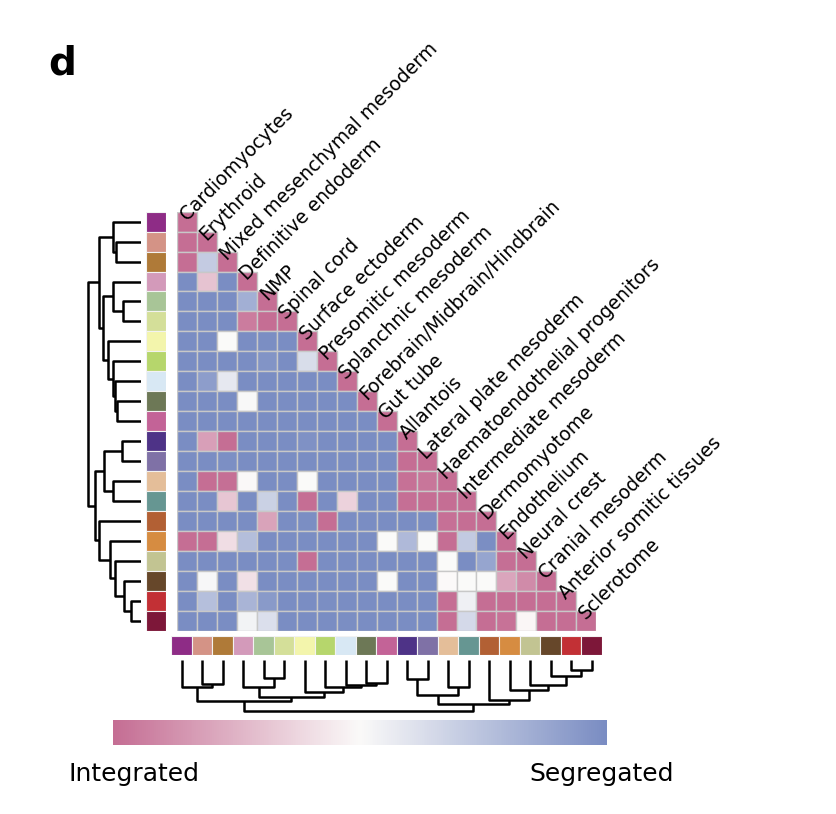

In [4]:
selected = OUTPUT_DIR / "final_figure.png"
for path in (selected, OUTPUT_DIR / "final_figure.pdf", OUTPUT_DIR / "plotting_code.py",
             OUTPUT_DIR / "tables/colormap.yaml", OUTPUT_DIR / "tables/analysis_metadata.json",
             OUTPUT_DIR / "reports/reproduction_report.md"):
    assert path.is_file(), f"Missing final artifact: {path}; inspect transcript.log."
print(selected.relative_to(REPO_ROOT))
display(Image(filename=str(selected)))


## Reproduction report


In [5]:
report_path = OUTPUT_DIR / "reports/reproduction_report.md"
print(report_path.relative_to(REPO_ROOT))
display(Markdown(report_path.read_text()))


cached/figure_recreation_lohoff-2d/reports/reproduction_report.md


# Lohoff et al. 2d cell-cell contact map reproduction report

## Verification status

Accepted final figure:

- PNG: `project/outputs/final_figure.png`
- PDF: `project/outputs/final_figure.pdf`
- Plotting/analysis code: `project/outputs/plotting_code.py`

I inspected `project/outputs/final_figure.png` against the supplied reference `project/uploads/reference_lohoff-2d.png`.  The accepted PNG is a single square cell-cell contact heatmap panel with panel label `d`, row/column dendrograms, lower-triangular heatmap including the diagonal, cell-type annotation strips, diagonal labels, and the horizontal `Integrated` to `Segregated` scale.  It is **not** a diagnostic grid or comparison montage.  Diagnostic comparison images are retained separately under `project/outputs/figures/compare_figures_attempt*.png` and were not copied to the final PNG.

Image/file verification from the final inspection:

- Reference image size: 836 × 814 px, RGBA.
- Final PNG size: 836 × 814 px, RGBA.
- Final PNG is byte-identical to accepted attempt 2 (`project/outputs/figures/final_figure_attempt2.png`), MD5 `b45dc45f4b05c430d13b6d0d7a2bd406`.
- Reference MD5: `8a7f5831bd93a980bff1df19d6405e58`.

## Supplied inputs and fields used

Supplied inputs only were used:

- Dataset: `library/datasets/dataset_lohoff_et_al_seqfish.h5ad`
- Instructions: `project/uploads/instructions_lohoff-2d.md`
- Reference panel: `project/uploads/reference_lohoff-2d.png`

Fields used from the H5AD, as recorded in `project/outputs/tables/contact_statistics_metadata.json` and propagated to `project/outputs/tables/analysis_metadata.json`:

- Cell-type label column: `obs['celltype_mapped_refined']`
- Spatial coordinate key: `obsm['spatial']`
- Embryo and z-slice parsing from observation IDs using regex: `^embryo(?P<embryo>[^_]+)_Pos(?P<pos>[^_]+)_cell(?P<cell>[^_]+)_z(?P<z>[^_]+)$`
- Strata used for all graph construction and permutations: embryo/z-slice combinations parsed from cell IDs.

No external or prior TissueAgent/baseline reproduction was retrieved.  No cells, genes, labels, statistics, coordinates, or reference pixels were fabricated or pasted into the output.

## Exclusions and exact per-stratum sample sizes

Cells labeled `Low quality` in `celltype_mapped_refined` were excluded because that category is absent from the target panel.

Overall filtering:

- Cells before filtering: 19,416
- `Low quality` cells excluded: 1,645
- Cells after filtering: 17,771

Exact per-stratum totals and post-filter cell-type counts from `project/outputs/tables/per_stratum_counts.csv`:

| stratum | embryo | z | cells before filter | Low quality excluded | cells after filter | undirected 10-NN edges | Allantois | Anterior somitic tissues | Cardiomyocytes | Cranial mesoderm | Definitive endoderm | Dermomyotome | Endothelium | Erythroid | Forebrain/Midbrain/Hindbrain | Gut tube | Haematoendothelial progenitors | Intermediate mesoderm | Lateral plate mesoderm | Mixed mesenchymal mesoderm | Neural crest | NMP | Presomitic mesoderm | Sclerotome | Spinal cord | Splanchnic mesoderm | Surface ectoderm |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| embryo1_z2 | 1 | 2 | 11,005 | 876 | 10,129 | 56,934 | 37 | 72 | 438 | 455 | 122 | 268 | 666 | 175 | 1,837 | 885 | 443 | 348 | 663 | 337 | 517 | 60 | 245 | 46 | 1,439 | 553 | 523 |
| embryo1_z5 | 1 | 5 | 8,411 | 769 | 7,642 | 43,309 | 40 | 40 | 299 | 73 | 91 | 255 | 287 | 125 | 1,867 | 579 | 194 | 275 | 580 | 204 | 395 | 49 | 213 | 32 | 1,181 | 585 | 278 |

All 21 displayed labels were represented in both strata, so `project/outputs/tables/pair_support.csv` contains support count 2 for every label pair.

## Contact-network approximation and missing inputs

The instructions describe the original cell-neighborhood network as an expanded segmentation-polygon contact graph.  The supplied H5AD does **not** contain segmentation polygons and does **not** contain a stored neighbor/contact graph.  Therefore the documented fallback was used exactly:

- Build graph separately within each embryo/z stratum.
- Use spatial centroids from `obsm['spatial']`.
- Construct a symmetric, undirected 10-nearest-neighbor graph.
- Remove self edges.
- Count each undirected edge once.

This is a **centroid-neighbor approximation**, not the original expanded-polygon contact network.  This missing-input limitation can change observed edge counts, permutation null distributions, p-values, clustering, dendrogram topology, and the final visible heatmap values relative to the published/reference panel.

## Statistical computation

For each embryo/z stratum and each unordered cell-type pair `(a,b)`:

1. Count observed undirected graph edges joining labels `(a,b)`, producing `C_ab_observed`.
2. Randomly permute labels 500 times within the same stratum, sampling without replacement and preserving the stratum's label counts.
3. Use random seed 0, implemented as `numpy.random.default_rng(0)`.
4. For each permutation, count `C_ab_permuted`.
5. Compute the written statistic exactly as requested:

   `p_ab = mean(C_ab_permuted >= C_ab_observed)`

6. Average `p_ab` across strata where both labels are represented.  In this run all labels were represented in both strata, so every pair was averaged across the two strata.

Primary numeric outputs:

- Square mean p-value matrix: `project/outputs/tables/contact_probabilities.csv`
- Pair support counts: `project/outputs/tables/pair_support.csv`
- Per-stratum observed counts: `project/outputs/tables/observed_counts.csv`
- Per-stratum permutation summaries/counts: `project/outputs/tables/permuted_counts.csv`
- Per-stratum p-value matrices: `project/outputs/tables/per_stratum_contact_probabilities.csv`
- Long-form plotted values: `project/outputs/tables/plotted_data.csv`
- Machine-readable statistics metadata: `project/outputs/tables/contact_statistics_metadata.json`
- Machine-readable analysis metadata: `project/outputs/tables/analysis_metadata.json`

## Tail-probability interpretation discrepancy

The formula was intentionally kept unchanged: `p_ab = mean(C_ab_permuted >= C_ab_observed)`.

The prose in `instructions_lohoff-2d.md` says that small values are more segregated and large values more integrated.  For the written upper-tail formula above, the user explicitly noted that this prose reverses the intended interpretation for the requested reproduction: low `p_ab` indicates an observed excess of contacts relative to permutation, i.e. integration, while high `p_ab` indicates depletion/segregation.

This reproduction follows that explicit correction while retaining the formula:

- Low p-value end: pink, labeled `Integrated`.
- High p-value end: blue, labeled `Segregated`.

## Clustering and displayed matrix

The calculated mean matrix was clustered from the computed values, not forced to the published row order and not forced to the reference matrix values.

- Distance: Euclidean distance on rows of the full mean matrix.
- Linkage: complete linkage.
- Same calculated order applied to rows and columns.
- Cluster order JSON: `project/outputs/tables/cluster_order.json`
- Linkage table: `project/outputs/tables/linkage.csv`

Calculated label order used in the accepted figure:

1. Cardiomyocytes
2. Erythroid
3. Mixed mesenchymal mesoderm
4. Definitive endoderm
5. NMP
6. Spinal cord
7. Surface ectoderm
8. Presomitic mesoderm
9. Splanchnic mesoderm
10. Forebrain/Midbrain/Hindbrain
11. Gut tube
12. Allantois
13. Lateral plate mesoderm
14. Haematoendothelial progenitors
15. Intermediate mesoderm
16. Dermomyotome
17. Endothelium
18. Neural crest
19. Cranial mesoderm
20. Anterior somitic tissues
21. Sclerotome

The final render displays the lower triangle including the diagonal.  `project/outputs/tables/plotted_data.csv` records all displayed cell pairs, their matrix indices, contact probabilities, pair support, triangle status, and interpretation string.

## Colors estimated from the reference

Cell-type annotation-strip colors were estimated from the supplied raster reference image and written to `project/outputs/tables/colormap.yaml`.  The reference order was used only to associate names with measured annotation-strip colors; it was **not** used to force the final heatmap order.  Because the reference is a raster image with anti-aliasing, the colors are estimates rather than exact original vector palette values.

Estimated cell-type color mapping used:

| Cell type | Hex color |
|---|---|
| Neural crest | `#c2c492` |
| Dermomyotome | `#b26034` |
| Cranial mesoderm | `#66472a` |
| Anterior somitic tissues | `#c23035` |
| Sclerotome | `#7d1739` |
| Endothelium | `#d68c41` |
| Erythroid | `#d49386` |
| Haematoendothelial progenitors | `#e4be99` |
| Intermediate mesoderm | `#669692` |
| Allantois | `#4e3387` |
| Lateral plate mesoderm | `#7f71a6` |
| Surface ectoderm | `#f3f5ac` |
| Mixed mesenchymal mesoderm | `#af7a38` |
| Splanchnic mesoderm | `#d8e8f4` |
| Presomitic mesoderm | `#b6d66c` |
| Definitive endoderm | `#d39aba` |
| NMP | `#a8c597` |
| Spinal cord | `#d4df99` |
| Cardiomyocytes | `#8e2c86` |
| Forebrain/Midbrain/Hindbrain | `#6d7856` |
| Gut tube | `#c36397` |

Estimated continuous heatmap scale colors:

- Low p / `Integrated`: `#c56e94`
- Midpoint: `#fbfaf9`
- High p / `Segregated`: `#7a8dc3`

## Figure-reproduction verification and attempts

Automated comparison was run after each render using the figure-reproduction comparison workflow.  The comparison images are diagnostic artifacts only and are not the final figure.

| Attempt | Reproduction path | SSIM | pHash Hamming | ORB good matches | Palette mean ΔE | Geometry clean | Outcome |
|---:|---|---:|---:|---:|---:|---|---|
| 1 | `project/outputs/figures/final_figure_attempt1.png` | 0.5504 | 4 | 109 | 9.29 | true | Structurally close; diagonal labels were high/clipped for the calculated order. |
| 2 | `project/outputs/figures/final_figure_attempt2.png` | 0.5518 | 4 | 96 | 10.03 | true | Accepted; label placement adjusted and copied byte-for-byte to `project/outputs/final_figure.png`. |

Attempt 2 geometry/orientation checks:

- Original and reproduced canvases have the same size and aspect ratio.
- Best orientation variant: `as_is`.
- Orientation suspect: `false`.
- Geometry findings: none; `clean=true`.

## Visual comparison to the reference

Structural matches observed in the accepted PNG:

- One panel, labeled `d`, on a white background.
- Square heatmap layout with lower triangle only and diagonal included.
- Both left and bottom dendrograms are present.
- Colored annotation strips are present at the left and bottom of the matrix.
- Diagonal cell-type labels are rotated similarly to the reference.
- A horizontal continuous scale is present below the heatmap, with `Integrated` on the pink/left side and `Segregated` on the blue/right side.
- The final PNG is the requested figure itself, not a target/reproduction/overlay comparison montage.

Expected and unresolved visual differences:

- The row/column order differs from the reference because the user requested clustering the **calculated** mean matrix and explicitly said not to force the published row order.  The reference begins with labels such as `Neural crest`, whereas the calculated order begins with `Cardiomyocytes`.
- The heatmap cell values and color pattern differ from the reference because the supplied H5AD lacks the original expanded segmentation-polygon contact network and a stored neighbor graph; the output therefore uses a centroid 10-NN approximation.
- Dendrogram topology differs for the same reason: it is derived from the recalculated mean p-value matrix rather than from the published matrix.
- Some label spacing, text placement, line weights, and strip colors are close but not identical to the raster reference; the palette was estimated from anti-aliased reference pixels.
- The reference likely reflects the original polygon-expansion contact network and publication rendering.  Those missing inputs and exact rendering details cannot be recovered from the supplied files.

These residual differences are documented limitations, not unaddressed structural defects.  The final accepted PNG satisfies the requested computation and figure specification using only the supplied data and instructions.
